# Capa 1: Stuff+

## ¿Qué queremos que haga?

Para un lanzamiento tendremos de entradas: 
$$ V_0, \omega,\text{spin axis},r_0, \rho$$

Queremos obtener una trayectoria y una velocidad: 
$$ r(t)=(x(t),y(t),z(t))$$ $$v(t)=(v_x (t),v_y (t), v_z (t))$$

Apartir de ahí vamos a calcular más variables como:
- velocidad
- movimiento vertical
- movimiento horizontal
- tiempo de vuelo
- entre otras

Estas variables son con las que vamos a alimentar a nuestro modelo de Stuff+


Primero debemos establecer varias cosas
Tomemos $$ x=\text{dirección hacia el plato}$$ $$y=\text{dirección horizontal lateral}$$ $$z=\text{altura}$$

Además, la gravedad es $$g=\begin{pmatrix} 0 \\ 0 \\ -g \end{pmatrix} \qquad, \text{con} \quad g=9.81 m/s^{2}$$

Definimos $$r(t)=\begin{pmatrix} x(t) \\ y(t) \\ z(t) \end{pmatrix} \quad \text{y} \quad v(t)=\begin{pmatrix} v_x(t) \\ v_y(t) \\ v_z(t) \end{pmatrix}$$

Por definición, $$\frac{dr}{dt}=v$$
$$\Rightarrow \frac{dx}{dt}=v_x,\quad \frac{dy}{dt}=v_y,\quad \frac{dz}{dt}=v_z$$

## Primera parte

El modelo lo voy a ir construyendo de forma escalonada, más que nada para tener una clara comprensión de lo que va a hacer y que no se obtenga de una forma tan agresiva, poco a poco vamos a ir agregando lo del drag y el efecto Magnus.

La segunda ley de Newton plantea: $$ma=mg \Rightarrow a=g$$
$$\Rightarrow \frac{dv}{dt} =\begin{pmatrix} 0 \\ 0 \\ -g \end{pmatrix}$$

Así, nuestro nuevo sistema o nuestro $\textbf{modelo 0}$ es:
$$ \dot{x}=v_x \\ \dot{y}=v_y \\ \dot{z}=v_z \\ \dot{v}_x=0 \\ \dot{v}_y=0 \\ \dot{v}_z=-g$$

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

In [6]:
#En este primer modelo fije las constantes manualmente
#Lo ideal es que para el modelo final esto venga de la base
g = 9.81

V0_mph = 95 #OJO: esta en millas
V0 = V0_mph * 0.44704 #en m/s^2

r0 = np.array([0.0, 0.0, 1.8]) #suponemos una altura inicial aproximada
v0 = np.array([V0, 0.0, 0.0]) #inicialmente la pelota viaja horizontalmente


#sistema de ecuaciones
def modelo_gravedad(t, estado):

    x, y, z, vx, vy, vz = estado

    dxdt = vx
    dydt = vy
    dzdt = vz

    dvxdt = 0
    dvydt = 0
    dvzdt = -g

    return [
        dxdt,
        dydt,
        dzdt,
        dvxdt,
        dvydt,
        dvzdt
    ]

El vector de estado es $y=(x,y,z,v_x,v_y,v_z)$ de esta forma vamos a poder trabajar con `solve_ivp`` que toma el sistema como $\frac{dy}{dt}=f(t,y)$
Lo que va a hacer es tomar $y(t_0)$ y calcular cada $t$ hasta obtener una aproximación de $y(t)$ que en nuestro caso es el vector de estado

Lo siguiente es ver el tiempo de simulación

In [7]:
#Por lo general el lanzamiento tarda décimas de segundo en llegar, esto es un inicial
t_span = (0, 0.5)

t_eval = np.linspace(0, 0.5, 300)

sol = solve_ivp(
    modelo_gravedad,
    t_span,
    np.concatenate([r0, v0]),
    t_eval=t_eval
)

sol.y[0]  # x
sol.y[1]  # y
sol.y[2]  # z
sol.y[3]  # vx
sol.y[4]  # vy
sol.y[5]  # vz

array([ 0.        , -0.01640468, -0.03280936, -0.04921405, -0.06561873,
       -0.08202341, -0.09842809, -0.11483278, -0.13123746, -0.14764214,
       -0.16404682, -0.18045151, -0.19685619, -0.21326087, -0.22966555,
       -0.24607023, -0.26247492, -0.2788796 , -0.29528428, -0.31168896,
       -0.32809365, -0.34449833, -0.36090301, -0.37730769, -0.39371237,
       -0.41011706, -0.42652174, -0.44292642, -0.4593311 , -0.47573579,
       -0.49214047, -0.50854515, -0.52494983, -0.54135452, -0.5577592 ,
       -0.57416388, -0.59056856, -0.60697324, -0.62337793, -0.63978261,
       -0.65618729, -0.67259197, -0.68899666, -0.70540134, -0.72180602,
       -0.7382107 , -0.75461538, -0.77102007, -0.78742475, -0.80382943,
       -0.82023411, -0.8366388 , -0.85304348, -0.86944816, -0.88585284,
       -0.90225753, -0.91866221, -0.93506689, -0.95147157, -0.96787625,
       -0.98428094, -1.00068562, -1.0170903 , -1.03349498, -1.04989967,
       -1.06630435, -1.08270903, -1.09911371, -1.11551839, -1.13

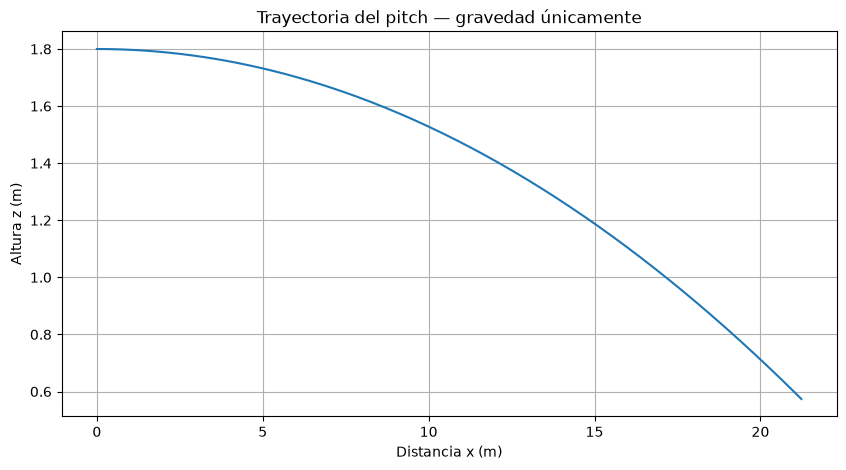

In [8]:
plt.figure(figsize=(10, 5))

plt.plot(sol.y[0], sol.y[2])

plt.xlabel("Distancia x (m)")
plt.ylabel("Altura z (m)")
plt.title("Trayectoria del pitch — gravedad únicamente")

plt.grid()
plt.show()

En este $\textbf{modelo 0}$ al solo tener gravedad la solución ya la tenemos.
Como $$\frac{dv_x}{dt}=0 \quad \Rightarrow \quad v_x(t)=v_0$$
Además, si inicialmente pasa que $$v_z(0)=0 \quad \Rightarrow \quad v_z(t)=-gt$$
Entonces, $$z(t)=z_0 - \frac{1}{2}gt^{2}$$
Pero también teniamos que $$x(t)=V_0 t$$
$$\Rightarrow t=\frac{x}{V_0}$$ $$\Rightarrow z(x)=z_0-\frac{g}{2V_0 ^{2}}x^{2}$$

Esto es nuestra parábola, compararemos esta solución con la trayectoria anterior y si lo hicimos bien, ambas curvas van a ser prácticamente idénticas. De ser así, lo tomaremos como que nuestro integrador y condiciones iniciales funcionan bien 

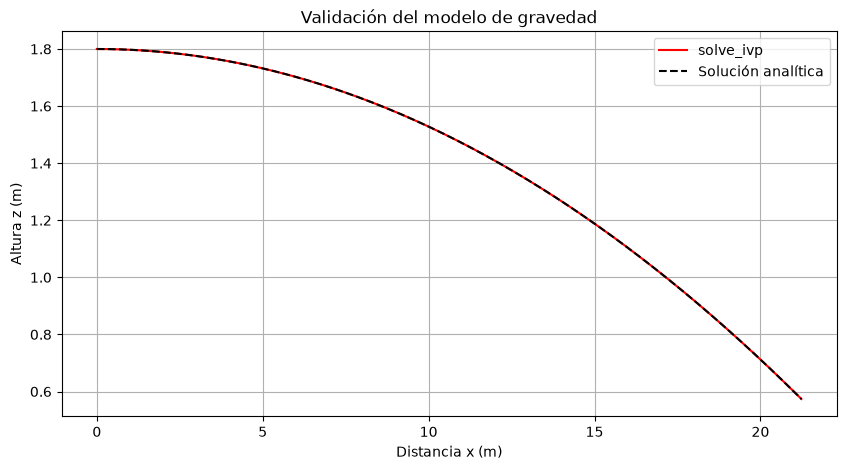

In [9]:
z_teorica = r0[2] - (g / (2 * V0**2)) * sol.y[0]**2

plt.figure(figsize=(10, 5))

plt.plot(sol.y[0], sol.y[2], "r",label="solve_ivp")
plt.plot(sol.y[0], z_teorica, "--k", label="Solución analítica")

plt.xlabel("Distancia x (m)")
plt.ylabel("Altura z (m)")
plt.title("Validación del modelo de gravedad")

plt.legend()
plt.grid()
plt.show()

Ahora si, vamos a agregar el Drag (resistencia del aire)

La fuerza de resistencia es: $$F_D=-\frac{1}{2}\rho AC_D|v|v \quad, \text{donde} \ A=\pi R^{2}$$

A es el área transversal de la bola y R su radio, $C_D$ es el coeficiente de arrastre y $\rho$ la densidad del aire

La magnitud de la velocidad es : $$|v|=\sqrt{v_x ^{2} + v_y ^{2}+ v_z ^{2}} $$

Entonces, $$F_D=-\frac{1}{2}\rho AC_D|v| \left(\begin{array}{cc} v_x\\v_y\\v_z \end{array}\right)$$

Dividiendo entre $m$: $$a_D=-\frac{\rho AC_D}{2m}|v| \left(\begin{array}{cc} v_x\\v_y\\v_z \end{array}\right)$$

Así cada componente queda como: 
$$\frac{dv_x}{dt}=-\frac{\rho AC_D}{2m}|v|v_x$$
$$\frac{dv_y}{dt}=-\frac{\rho AC_D}{2m}|v|v_y$$
$$\frac{dv_z}{dt}=-g-\frac{\rho AC_D}{2m}|v|v_z$$

Las ecuaciones estan ligadas porque la aceleración va a depender de $$|v|$$


In [10]:
def modelo_drag(t, estado):

    x, y, z, vx, vy, vz = estado

    v = np.array([vx, vy, vz])

    velocidad = np.linalg.norm(v)

    # Aceleración por drag
    factor_drag = -(rho * A * Cd) / (2 * m)

    a_drag = factor_drag * velocidad * v

    # Gravedad
    a_gravedad = np.array([0.0, 0.0, -g])

    # Aceleración total
    aceleracion = a_gravedad + a_drag

    dxdt = vx
    dydt = vy
    dzdt = vz

    dvxdt = aceleracion[0]
    dvydt = aceleracion[1]
    dvzdt = aceleracion[2]

    return [
        dxdt,
        dydt,
        dzdt,
        dvxdt,
        dvydt,
        dvzdt
    ]

In [11]:
#Suponiendo unos valores aproximados para esta prueba
#Lo ideal va a ser no poner estos a mano, sino sustituirlos con datos reales
m = 0.145 #kg aprox
R = 0.0367 #radio aprox en metros

A = np.pi * R**2
rho = 1.2
Cd = 0.5
# ----------------------------

#volvemos a resolver 
sol_drag = solve_ivp(
    modelo_drag,
    t_span,
    np.concatenate([r0, v0]),
    t_eval=t_eval
)

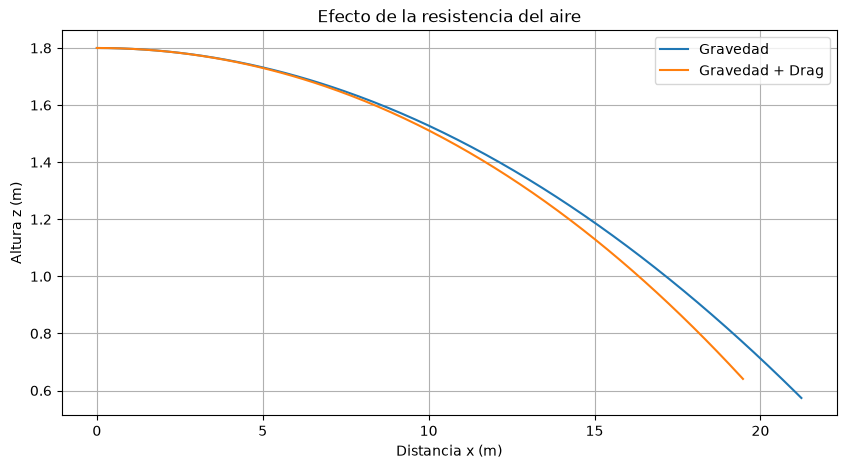

In [12]:
plt.figure(figsize=(10, 5))

plt.plot(
    sol.y[0],
    sol.y[2],
    label="Gravedad"
)

plt.plot(
    sol_drag.y[0],
    sol_drag.y[2],
    label="Gravedad + Drag"
)

plt.xlabel("Distancia x (m)")
plt.ylabel("Altura z (m)")

plt.title("Efecto de la resistencia del aire")

plt.legend()
plt.grid()

plt.show()

Ya tenemos gravedad y Drag, falta agregar el efecto Magnus

Nuestro punto de partida es $$m\frac{dv}{dt}=mg+F_D+F_M$$
Ya sabemos que $$F_D=-\frac{1}{2}\rho AC_D|v|v$$ pero además también introducimos $$F_M=\frac{1}{2}\rho AC_L|v|^{2} \frac{\omega \times v}{|\omega \times v|}$$
$$\Rightarrow \frac{dv}{dt}= g-\frac{\rho AC_D}{2m}|v|v+\frac{\rho AC_L}{2m}|v|^{2}\frac{\omega \times v}{|\omega \times v|}$$

$C_L$ es llamado el coeficiente de sustentación, además $\omega \times v$ es el que va a determinar hacia donde se desvía la pelota 

Observación importante:
$$\omega=\left(\begin{array}{cc} \omega_x\\\omega_y\\\omega_z \end{array}\right) \quad y \quad v=\left(\begin{array}{cc} v_x\\v_y\\v_z \end{array}\right)$$
$$(\omega \times v)\cdot v=0$$
Es decir, $\quad \omega \times v \perp v$

En otras palabras la fuerza de Magnus es perpendicular al movimiento

Haciendo un primer ejemplo de backspin
Vamos a suponer que la pelota viaja solo hacia $x$:
$$v=\left(\begin{array}{cc} V\\0\\0 \end{array}\right) \quad \text{y} \quad \omega=\left(\begin{array}{cc} 0\\-\omega\\0 \end{array}\right), \qquad \omega \quad \text{es un eje de rotación}$$
$$\Rightarrow \omega \times v= \left(\begin{array}{cc} 0\\0\\\omega V \end{array}\right)$$
$$\Rightarrow F_M||+\hat{z}$$

Esto nos dice que la fuerza de Magnus apunta hacia arriba

Si la velocidad angular de los datos viene en rpm
$$ 1 \quad \text{revolución} = 2\pi  rad$$
$$ 1 \quad \text{minuto}=60  s$$

$$\Rightarrow \omega = RPM\frac{2\pi}{60}$$

OJO: Esto solo lo vamos a utilizar si la rotación viene en revoluciones por minuto (rpm) para convertirla en radianes por segundo

In [13]:
#ejemplo particular
spin_rpm = 2400

omega_mag = spin_rpm * 2 * np.pi / 60

print(omega_mag)

spin_axis = np.array([0.0, -1.0, 0.0]) #dirección del eje de rotación

omega_vector = omega_mag * spin_axis



251.32741228718345


$C_L$ no va a ser una constante arbitraria, entoces hay que construirla, empecemos definiendo $$S=\frac{R\omega_\perp}{|v|}, \quad \text{donde} \quad \omega_\perp=\frac{|\omega \times v|}{|v|}$$
$$\Rightarrow S= \frac{R|\omega \times v|}{|v|^{2}}$$

En nuestro ejemplo teniamos que $\omega \perp v$: $$\omega_\perp=\omega$$
$$\Rightarrow S=\frac{R\omega}{V}$$


In [14]:
R = 0.0367
S = R * omega_mag / V0

print(S) #s aproximado con los valores de nuestro ejemplo

0.21718805407592473


Una parametrización bastante utilizada en el baseball es:
$$C_L(S)=
\begin{cases}
   1.5S, \qquad \qquad S\leq 0.1 \\
    0.09+0.6S, \quad S> 0.1
\end{cases}$$

Esta nosotros la vamos a utilizar para encontrar nuestro coeficiente de sustentación


En nuestro ejemplo, $S\approx0.217 > 0.1$
Entonces $$C_L =0.09+0.6(0.217)$$
$$\Rightarrow C_L \approx 0.220$$

In [15]:
#coeficiente de sustentación
def coeficiente_lift(S):

    if S <= 0.1:
        return 1.5 * S
    else:
        return 0.09 + 0.6 * S

Una observación importante que vamos a tomar en cuenta es que para $$\frac{\omega \times v}{|\omega \times v|}$$ en caso de que $\omega \times v=0$ estariamos dividiendo sobre cero y eso sucede solo cuando el eje de rotación es paralelo a la trayectoria. 
En este caso $$\omega_\perp = 0 \Rightarrow S=0$$
Así, la fuerza de Magnus: $$F_M=0$$

In [16]:
def modelo_magnus(t, estado):

    # -------------------------
    # Estado
    # -------------------------

    x, y, z, vx, vy, vz = estado

    v = np.array([vx, vy, vz])

    velocidad = np.linalg.norm(v)

    # -------------------------
    # Gravedad
    # -------------------------

    a_gravedad = np.array([
        0.0,
        0.0,
        -g
    ])

    # -------------------------
    # Drag
    # -------------------------

    factor_drag = -(rho * A * Cd) / (2 * m)

    a_drag = factor_drag * velocidad * v

    # -------------------------
    # Magnus
    # -------------------------

    cross = np.cross(omega_vector, v)

    magnitud_cross = np.linalg.norm(cross)

    if magnitud_cross > 1e-12:

        omega_perpendicular = magnitud_cross / velocidad

        S = R * omega_perpendicular / velocidad

        Cl = coeficiente_lift(S)

        direccion_magnus = cross / magnitud_cross

        a_magnus = (
            (rho * A * Cl) / (2 * m)
            * velocidad**2
            * direccion_magnus
        )

    else:

        a_magnus = np.zeros(3)

    # -------------------------
    # Aceleración total
    # -------------------------

    aceleracion = (
        a_gravedad
        + a_drag
        + a_magnus
    )

    # -------------------------
    # Derivadas
    # -------------------------

    dxdt = vx
    dydt = vy
    dzdt = vz

    dvxdt = aceleracion[0]
    dvydt = aceleracion[1]
    dvzdt = aceleracion[2]

    return [
        dxdt,
        dydt,
        dzdt,
        dvxdt,
        dvydt,
        dvzdt
    ]

In [17]:
sol_magnus = solve_ivp(
    modelo_magnus,
    t_span,
    np.concatenate([r0, v0]),
    t_eval=t_eval
)

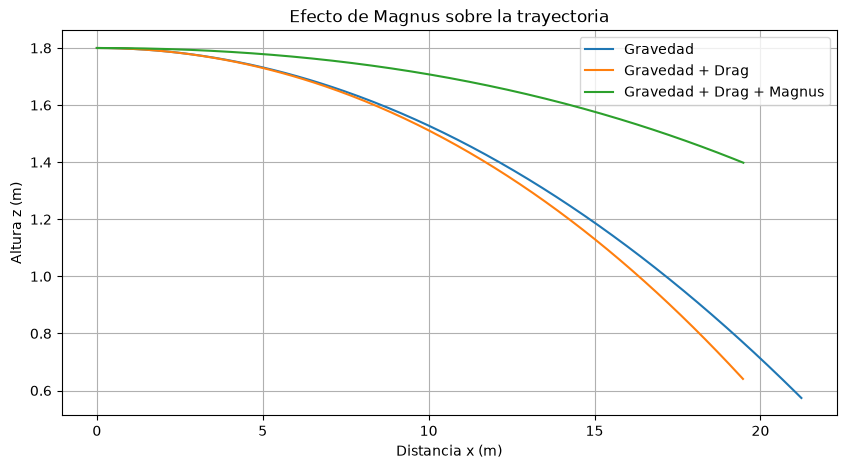

In [18]:
#lanzamiento con backspin
plt.figure(figsize=(10, 5))

plt.plot(
    sol.y[0],
    sol.y[2],
    label="Gravedad"
)

plt.plot(
    sol_drag.y[0],
    sol_drag.y[2],
    label="Gravedad + Drag"
)

plt.plot(
    sol_magnus.y[0],
    sol_magnus.y[2],
    label="Gravedad + Drag + Magnus"
)

plt.xlabel("Distancia x (m)")
plt.ylabel("Altura z (m)")

plt.title("Efecto de Magnus sobre la trayectoria")

plt.legend()
plt.grid()

plt.show()

Haciendo otro caso para ver como se comporta Magnus, hagamos un caso A y B

Caso A: $$ \omega =0$$
Caso B: $$\omega=2400rpm$$

El resto lo vamos a mantener igual

In [19]:
omega_vector = np.array([0.0, 0.0, 0.0])

sol_sin_spin = solve_ivp(
    modelo_magnus,
    t_span,
    np.concatenate([r0, v0]),
    t_eval=t_eval
)

In [20]:
omega_vector = omega_mag * spin_axis

sol_con_spin = solve_ivp(
    modelo_magnus,
    t_span,
    np.concatenate([r0, v0]),
    t_eval=t_eval
)

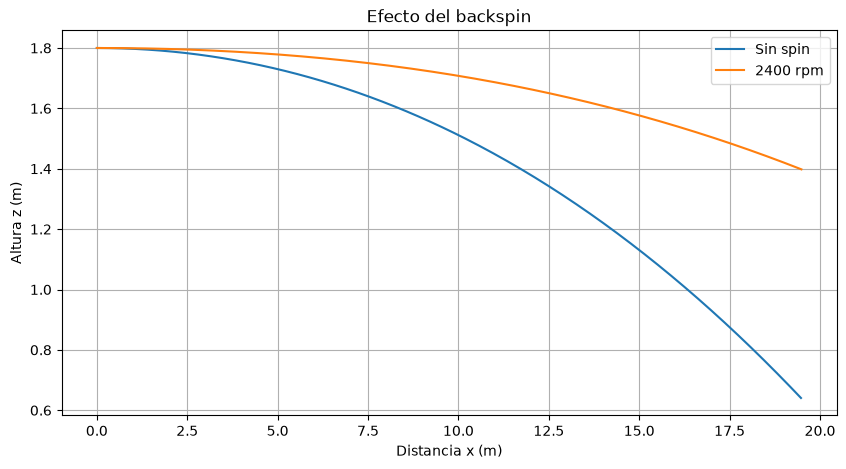

In [21]:
plt.figure(figsize=(10, 5))

plt.plot(
    sol_sin_spin.y[0],
    sol_sin_spin.y[2],
    label="Sin spin"
)

plt.plot(
    sol_con_spin.y[0],
    sol_con_spin.y[2],
    label="2400 rpm"
)

plt.xlabel("Distancia x (m)")
plt.ylabel("Altura z (m)")

plt.title("Efecto del backspin")

plt.legend()
plt.grid()

plt.show()

In [22]:
#comprobación de que nuestro backspin está generando lift
#por Magnus la aceleración que se produce debe ir hacia arriba
v_test = np.array([V0, 0.0, 0.0])

cross_test = np.cross(
    omega_vector,
    v_test
)

print("omega x v =", cross_test)

omega x v = [   -0.             0.         10673.57360694]


Ahora, vamos a comenzar a hacer las modificaciones para que nuestro modelo funcione para lo que relmente queremos, baseball

Lo primero es que vamos a cambiar de eje, tenemos que $$ \omega= \left(\begin{array}{cc} 0\\-\omega\\0 \end{array}\right) \rightarrow \text{backspin}$$

Si ahora ponemos $$ \omega=\left(\begin{array}{cc} 0\\+\omega\\0 \end{array}\right)$$

Va a invertir la fuerza, entonces $$\omega \times v \rightarrow -(\omega \times v)$$

Y eso es lo que nos va a dar topspin, ósea que la fuerza de Magnus va a apuntar hacia abajo

In [23]:
spin_axis = np.array([0.0, 1.0, 0.0])

omega_vector = omega_mag * spin_axis

Falta ver como se produce el movimiento horizontal

Tenemos que $$\omega= \left(\begin{array}{cc} 0\\0\\\omega \end{array}\right) \Rightarrow \omega \times v=\left(\begin{array}{cc} 0\\\omega V\\0 \end{array}\right)$$

Entonces ahora $$F_{M_y}>0$$
Así, la bola de desvía lateralmente


Lo siguiente que vamos a hacer es generalizar el $\text{spin axis}$ 

Tenemos $$v=(v_x,v_y,v_z) \quad \text{y} \quad \omega=(\omega_x,\omega_y,\omega_z)$$
recordando que $\omega$ es quien determina hacia dónde está orientado el giro de la bola

El spin rate solo nos da la magnitud $$|\omega|=\omega$$

Sin embargo no nos da la dirección y por eso hay que separar $$\omega=\omega\hat{s}$$

Donde,

$\omega=$ velocidad angular en rad/s

$\hat{s}=$ vector unitario retresentando el eje de giro


Lo que no queremos es escribir a manita quien es el spin axis, sino que recibamos un ángulo de spin y que el modelo lo convierta en un vector. 

Para eso definimos $\phi$ un ángulo en el plano perpendicular a la trayectoria

Sea $$\hat{v}=\frac{v}{|v|}$$ Este vector va a apuntar en la dirección que viaja la bola.

Ahora tomemos $\hat{e}_1$ y $\hat{e}_2$, vectores perpendiculares a $\hat{v}$ que forman una base del plano perpendicular

Así, definimos $$\hat{s}=\cos(\phi)\hat{e}_1+\sin(\phi)\hat{e}_2$$ y $$\omega=\omega[\cos(\phi)\hat{e}_1+\sin(\phi)\hat{e}_2]$$

Una observación importante es que usamos el plano perpendicular porque la componente $\omega$ paralela a la velocidad no produce Magnus. 

Recordemos de $F_M$ es proporcional a $\omega \times v$

Entonces, si $$\omega||v \Rightarrow \omega \times v=0$$
$$F_M=0$$

Por eso lo que nos interesa es $$\omega_\perp =\frac{|\omega \times v|}{|v|}$$ y esto ya estaba en el parámetro $S$ que definimos más atrás, $$S=\frac{R|\omega \times v|}{|v|^{2}}$$

En particular esto nos dice que el efecto Magnus depende de la velocidad, spin rate y la orientación del spin simultaneamente. 


Para controlar el movimiento vertical y horizontal tomamos un ángulo $\phi$

Por ejemplo si mantenemos $$v=(V,0,0)$$
Podemos definir $$\hat{s}=\left(\begin{array}{cc} 0\\\cos(\phi)\\\sin(\phi) \end{array}\right)$$
$$\Rightarrow \omega =\omega \left(\begin{array}{cc} 0\\\cos(\phi)\\\sin(\phi) \end{array}\right)$$

Además, $$\omega \times v= \left(\begin{array}{cc} 0\\\omega V\sin(\phi)\\-\omega V\cos(\phi) \end{array}\right)$$

La $a_M$ es proporcional a $$\left(\begin{array}{cc} 0\\\sin(\phi)\\-\cos(\phi) \end{array}\right)$$

Si $\phi=90^{\circ}$, $$a_M \quad \text{proporcional} \quad \left(\begin{array}{cc} 0\\1\\0 \end{array}\right)$$ Magnus va hacia abajo

Si $\phi=0^{\circ}$, $$a_M \quad \text{proporcional} \quad \left(\begin{array}{cc} 0\\0\\-1 \end{array}\right)$$ Magnus va completamente lateral

Si $\phi=180^{\circ}$, $$a_M \quad \text{proporcional} \quad \left(\begin{array}{cc} 0\\0\\1 \end{array}\right)$$ Magnus va hacia arriba

Solo cambiando $\phi$ generamos diferentes patrones de movimiento

In [24]:
import numpy as np

def spin_vector(rpm, phi):
    
    # rpm -> rad/s
    omega = rpm * 2*np.pi / 60
    
    # eje de spin
    spin_axis = np.array([
        0,
        np.cos(phi),
        np.sin(phi)
    ])
    
    # normalizar
    spin_axis = spin_axis / np.linalg.norm(spin_axis)
    
    # vector de velocidad angular
    omega_vector = omega * spin_axis
    
    return omega_vector

In [25]:
#EJEMPLO:
rpm = 2400

omega_vector = spin_vector(
    rpm,
    np.deg2rad(180)
)

print(omega_vector)

[ 0.00000000e+00 -2.51327412e+02  3.07787311e-14]


Con esto ya solo recibimos $RPM,\phi$ y automáticamente los convertimos en $\omega$, con eso calculamos $S$ y $C_L$ para finalmente obtener que $$a_M=\frac{\rho AC_L}{2m}|v|^{2}\frac{\omega \times v}{|\omega \times v|}$$

Tenemos nuestra trayectoria $$r(t)=\left(\begin{array}{cc} x(t)\\y(t)\\z(t) \end{array}\right)$$
Recordando que:
- $x$: hacia el home plate
- $y$: movimiento lateral
- $z$: altura

Lo que queremos es ver cuánto se mueve la pelota respecto a una trayectoria de referencia, principalmente hablabos de estas 2 variables:
$$ HB= \text{Horizontal} \ \text{Break}$$
$$ IVB= \text{Induced} \ \text{Vertical} \ \text{Break}$$

Primero tracemos nuestra trayectoria de referencia, tenemos 2 bolas con las mismas condiciones:
- velocidad inicial
- posición inicial
- drag
- gravedad

Lo que va a cambia es que la bola A no va a tener efecto Magnus, es decir $$C_L=0$$, a esta la llamaremos $r_0(t)$


A la bola que si tiene efecto Magnus $$C_L>0$$ la llamaremos $r_M(t)$

Si inicialmente $v_y=0$ y no hay Magnus, $$y_0(t)=0$$
pero si agregamos Magnus, $$y_M(t) \neq 0$$

Por lo tanto $$HB=y_M(t_{plate})-y_0(t_{plate})$$
Por lo regular $$y_0(t_{plate}) \approx 0$$ $$\Rightarrow HB \approx y_M(t_{plate})$$




Ahora, falta ver quien es IVB, lo que queremos medir es el efecto vertical asociado al movimiento del lanzamiento respecto a una referencia sin Magnus
$$\Rightarrow IVB=z_M(t_{plate})-z_0(t_{plate})$$

Algo importante es que nuestra pelota no necesariamente va a empezar con $v_y=0, v_z=0$, en realidad el pitcher libera la bola con un ángulo determinado

Entonces para nuestra descomposición física de la trayectoria va a ser $$\text{trayectoria}_{obs}=\text{release}+\text{gravedad}+\text{drag}+\text{Magnus}$$

Matemáticamente:
$$r(t)=r_0+\int_{0}^{t}v(\tau)\ d\tau$$
$$v(t)=v_0+\int_{0}^{t}(g+a_D+a_M) \ d\tau$$

Empezemos a plantear este modelo, definimos $$HB=y_C(t_p)-y_B(t_p)$$ $$IVB=z_C(t_p)-z_B(t_p)$$
Donde: \
$C=$ gravedad + drag + Magnus \
$B=$ gravedad + drag

Con eso vamos a de cierta forma aislar el efecto Magnus para no confundir el movimiento inducido por spin con la caída natural de la bola

In [26]:
def calcular_break(sol_base, sol_magnus, t_plate):
    
    # posición en el instante del plato
    r_base = sol_base.sol(t_plate)[:3]
    r_magnus = sol_magnus.sol(t_plate)[:3]
    
    # Diferencias
    HB = r_magnus[1] - r_base[1]
    IVB = r_magnus[2] - r_base[2]
    
    return HB, IVB

También hay que determinar $t_\text{plate}$

Vamos a encontrar cuándo $x(t)=x_\text{plate}$
Algo importante a notar es que nuestro modelo debe detenerse justo cuando $x=x_\text{plate}$

In [27]:
def evento_plato(t, y):
    return y[0] - x_plate

evento_plato.terminal = True
evento_plato.direction = 1

In [ ]:
#con esta construcción vamos a tener en automático el momento en que la bola llega al plato
sol = solve_ivp(
    modelo, #falta asignar con cual modelo va a trabajar
    (0, 1),
    y0, #falta asignar
    events=evento_plato,
    dense_output=True
)

t_plate = sol.t_events[0][0]

Hasta este punto el modelo ya produce $HB$, $IVB$, $t_\text{flight}$, $V_\text{plate}$, $a_D$, $a_M$

Lo siguiente es hacer el modelo atmosférico que va a estar directamente relacionado con el modelo físico, esta parte va a ser la que nos de las variaciones dependiendo de la densidad de donde se juegue

La densidad del aire depende de $$\rho=\frac{P}{R_\text{air}T}$$
con:
- $P=$ presión atmosférica
- $T=$ temperatura absoluta
- $R_\text{air} \approx 287.05 \ J/(kg \ K)$

Además, recordemos que la densidad aparece directamente en $a_D$ y $a_M$, por lo mismo al aumentar o disminuir la densidad, ambas aceleraciones aumentan o disminuyen.

Físicamente, $$\rho=\rho(P,T)$$
En aire seco se puede utilizar nuestra ecuación antes dada, solo hay que notar que la temperatura este en Kelvin ($T_K =T_C +273.15$)

En condiciones atmosféricas comparables, para nuestro modelo va a pasar que $$\rho_\text{CDMX} <\rho_\text{nivel\ del\ mar}$$ 
¿Por qué?, La presión atmosférica disminuye a mayor altitud, CDMX tiene una gran altitud en comparación con otras ciudades donde también se juega en la temporada, por eso mismo la densidad va a ser mayor a nivel del mar que en la CDMX


Primero utilizamos una aproximación de atmósfera estándar:
$$P(h) = P_0 \left( 1 - \frac{Lh}{T_0} \right)^{\frac{gM}{RL}}$$

donde aproximadamente:
- $P_0=101325\ Pa$
- $T_0=288.15\ K$
- $L=0.0065\ K/m$
- $g=9.80665\ m/s^{2}$
- $M=0.02895644\ kg/mol$
- $R=8.31447\ J/(mol\ K)$

Con esto vamos a poder calcular la presión aproximada a partir de la altitud

Lo que tenemos que adaptar son nuestras condiciones reales del estadio, esto porque el lanzamiento tiene muchas variantes como la hora, mes, temperatura, presión, condiciones meteorológicas. Por eso vamos a tomar $$P=P(h,t) \ y \ T=T(h,t)$$ Así lo único que vamos a darle directamente va a ser la temperatura y la presión según sea el caso, esto nos va a funcionar globalmente, pues así el modelo va a funcionar sin importar la localización del estadio o tener que hacer cambios "manuales" según el estadio, lo único que va a necesitar va a ser la $\rho$

In [28]:
R_air = 287.05

def densidad_aire(P, T_C):
    
    T_K = T_C + 273.15
    
    rho = P / (R_air * T_K)
    
    return rho

In [ ]:
#EJEMPLO
P = 80000       # Pa
T = 20          # °C

rho = densidad_aire(P, T)

print(rho)

0.9506979058472169


Recordando, $$F_D=-\frac{1}{2}\rho AC_D|v|v$$

$$\Rightarrow a_D=-\frac{\rho AC_D}{2m}|v|v$$

Entonces podemos definir $$K_D=\frac{\rho AC_D}{2m}$$
$$\Rightarrow a_D=-K_D|v|v$$
Con esto vemos que $K_D$ es proporcional a $\rho$

Además, $$F_M=-\frac{1}{2}\rho AC_L|v|^{2}\hat{n}$$

$$\Rightarrow a_M=-\frac{\rho AC_L}{2m}|v|^{2}\hat{n}$$

Entonces $$K_M=\frac{\rho AC_L}{2m}$$
$$\Rightarrow a_M=-K_M|v|^{2}\hat{n}$$
Por lo tanto $K_M$ es proporcional a $\rho$

Para cada lanzamiento real $i$ vamos a tener algo como:
$$X_i=(V_i,RPM,\theta_i,\rho_i,\dots)$$
Mientras que el modelo genera $$\hat{IVB}_i,\ \hat{HB}_i$$
Podemos calcular los errores para minimizarlos:
$$e_{IVB,i}=IVB_{i}^{\text{real}}-IVB_{i}^{\text{modelo}}$$
$$e_{HB,i}=HB_{i}^{\text{real}}-HB_{i}^{\text{modelo}}$$
$$\Rightarrow L=\frac{1}{N}\sum_{i=1}^{N}[e_{IVB,i}^{2}+e_{HB,i}^{2}]$$

Con esto lo que vamos a hacer más adelante básicamente va a ser una calibración de parámetros

Creamos $$\Delta IVB=IVB_{\text{real}}-IVB_{\text{modelo}}$$ $$\Delta HB=HB_{\text{real}}-HB_{\text{modelo}}$$
Con estas diferencias vamos a ver cuánto se desvía un lanzamiento de lo que nuestro modelo físico esperaba dadas sus condiciones

Lo ideal es que para cada lanzamiento queremos:

$$
\begin{array}{c|c}
\text{Variable} & \text{Símbolo}  \\ \hline
\text{Velocidad\ de\ salida} & V_0  \\
\text{Spin\ rate} & RPM \\
\text{Spin\ axis} & \omega \\
\text{Release\ position} & r_0 \\
\text{Release\ velocity} & v_0 \\
\text{Velocidad\ al\ plato} & V_p \\
\text{Horizontal\ break} & HB \\
\text{Induced vertical break} & IVB \\
\text{Temperatura} & T \\
\text{Presión} & P \\
\text{Altitud} & h \\
\end{array}
$$

Algo importante de notar es que puede que no tengamos todas como tal, las condiciones atmosféricas de no tenerlas las vamos a obtener del estadio, fecha y hora que haya en la base

Vamos a empezar con la calibración, primero aislamos el efecto del drag

Tomemos $$a=g+a_D$$ sin Magnus el parámetro pincipal va a ser $C_D$, entonce podemos definir $$C_D=\theta$$

Con dicha definición vamos a buscar el valor de $\theta$ que minimice el error entre la velocidad predicha al plato y la observada

Para cada lanzamiento $i$: 

La velocidad observada al plato es $$V_{p,i}^{\text{real}}$$
Nuestro modelo produce $$V_{p,i}^{\text{modelo}}(C_D)$$
$$\Rightarrow e_i=V_{p,i}^{\text{real}}-V_{p,i}^{\text{modelo}}$$
Con esto definimos $$L_D(C_D)=\frac{1}{N}\sum_{i=1}^{N}e_{i}^{2}$$

Lo que vamos a buscar es el valor de $C_D$ que minimice el error cuadrático

NOTA: $C_D$ no necesariamente va a ser constante, una versión que vamos demostrar que $$C_D=C_D(Re), \quad Re=\frac{\rho VD}{\mu}$$
En lo que eso pasa $C_D=\text{constante}$

In [ ]:
#va a ejecutar todos los lanzamientos y calculará L_D(C_D)
#solo concepto, no tiene bien definido quien es la función para el error
from scipy.optimize import minimize_scalar

resultado = minimize_scalar(
    funcion_error,
    bounds=(0.2, 0.8),
    method="bounded"
)

Cd_optimo = resultado.x

funcion_error(Cd)

Ya calibrado el drag, pasamos a $C_L(S)$
El modelo inicial que teniamos era
$$C_L(S)=
\begin{cases}
   1.5S, \qquad \qquad S\leq 0.1 \\
    0.09+0.6S, \quad S> 0.1
\end{cases}$$

Pero ¿qué tan bien puede reproducir los datos reales?
Podemos parametrizar $C_L$, escribimos $$C_L=a+bS$$, donde $a,b$ son los parámetros que vamos a estimar
$$\Rightarrow a_M=\frac{\rho A(a+bS)}{2m}|v|^{2}\hat{n}$$
buscamos $a,b$ que minimicen $L_M$

$$\Rightarrow L_M (a,b)=\frac{1}{N}\sum_{i=1}^{N}[e_{IVB,i}^{2}+e_{HB,i}^{2}]$$

Con esto lo que hacemos es estimar los parámetros aerodinámicos que minimizan el error entre las trayectorias predichas y los lanzamientos observados


Nuestras métricas van a ser las siguientes:
- HB: $$RMSE_{HB}=\sqrt{\frac{1}{N}\sum_i {(HB_{i}^{\text{real}}-HB_{i}^{\text{modelo}})^{2}}}$$
- IVB: $$RMSE_{IVB}=\sqrt{\frac{1}{N}\sum_i {(IVB_{i}^{\text{real}}-IVB_{i}^{\text{modelo}})^{2}}}$$
- Velocidad: $$RMSE_{V}=\sqrt{\frac{1}{N}\sum_i {(V_{i}^{\text{real}}-V_{i}^{\text{modelo}})^{2}}}$$ 
Además podemos calcular $$MAE=\frac{1}{N}\sum_i |e_i|$$

En este punto ya estamos más encaminados al Stuff+, con el lo que queremos medir es la calidad intrínseca del lanzamiento, en lo posible separandola de dónde fue lanzado y del resultado final.

Inicialmente vamos a construir un modelo que estime $$P(\text{evento\ favorable}\ |\ X)$$ donde el evento va a ser dependiendo de los datos que tengamos como:
- swing-and-miss
- chase
- called strike
- weak contact
Entre otros 

Un ejemplo es $$P(\text{whiff}\ |\ X)$$

OJO: Lo que queremos que represente principalmente el Stuff+ es la calidad física del lanzamiento, no hay que olvidarnos de eso

Comenzemos con una regresión logística:
$$P(Y=1 |\ X)=\frac{1}{1+e^{-z}}$$
donde: $$z=\beta_0+\beta_1V+\beta_2RPM+\beta_3IVB+\beta_4HB+\beta_5S+\dots$$

Por ejemplo, la probabilidad estimada de whiff sería:
$$P(Y=1 |\ X),\qquad \text{con}\ Y=\begin{cases} 1, \quad \text{whiff} \\ 0, \quad \text{no\ whiff} \end{cases} $$

Vamos a separar nuestras variables:
$$X_\text{physical}$$
Las variables que van a alimentar esta simulación son $$V_0, RPM, spin\ axis, r_0, v_0, \rho, T, P, h$$

Con las que vamos a comprobar si la simulación funciona las vamos a tener en $$Y_\text{physical}$$ y éstas van a ser $$ IVB_{\text{real}}, HB_{\text{real}}, V_{\text{plate,real}}$$

Por ultimo tendremos $$X_\text{stuff}$$, donde va a tener una forma como esta $$X_\text{stuff}=V_0, RPM, IVB, HB, S, extension, Release Height, Release Side, \rho, \dots$$ Esto va a servir más para nuestro modelo estadístico

Una distinción importante es la diferencia entre $V_0$ y $V_{\text{plate}}$. 

La primera es la velocidad inicial $V_0=|v(0)|$, mientras que $V_{\text{plate}}=|v(t_p)|$ donde $x(t_p)=x_\text{plate}$

El modelo debe predecir $$\hat{V}_\text{plate}$$ y podemos hacer la comparación: $$e_V=V_\text{plate}^\text{real}-\hat{V}_\text{plate}$$

$\textbf{NOTAS IMPORTANTES:}$

En dado caso que los datos no esten como el sistema de coordenadas que definimos, tenemos que construir una transformación para ajustarlos al modelo y que no haya cambios o errores importantes por ese detalle.
Recordemos el sistema esta definido como: $$x=\text{dirección\ hacia\ home}\\ y=\text{lateral}\\ z=\text{vertical}$$ $$r=\left(\begin{array}{cc} x\\y\\z \end{array}\right)$$
Ejemplo: $$\left(\begin{array}{cc} x\\y\\z \end{array}\right)_\text{modelo}=\left(\begin{array}{cc} 0&1&0\\1&0&0\\0&0&1 \end{array}\right)\left(\begin{array}{cc} x\\y\\z \end{array}\right)_\text{datos}$$

Otro punto importante es que si la base nos da $\theta_\text{spin}$ en grados, no la podemos asumir directamente como $\theta_\text{spin}=\phi$ de nuestro modelo. En términos generales se tendría que hacer $\theta_\text{datos}\rightarrow \hat{s}_\text{datos}\rightarrow \hat{s}_\text{modelo}$ y después $\omega=\omega\hat{s}_\text{modelo}$

Es importante que revisemos lo del spin porque un error de $90^\circ$ nos puede transformar el sentido de vertical a horizontal

Para nuestro modelo estadístico tomaremos variables o outcomes con las que posteriormente podamos construir distintos objetos estadísticos: $$Whiff=\begin{cases} 1,\quad \text{si\ hubo\ swing\ y\ miss}\\ 0,\quad \text{de\ otra\ forma} \end{cases}$$
$$Swing=\begin{cases} 1,\quad \text{si\ el\ bateador\ hizo\ swing}\\ 0,\quad \text{si\ no} \end{cases}$$
$$Contact=\begin{cases} 1,\quad \text{si\ hubo\ contacto}\\ 0,\quad \text{si\ no} \end{cases}$$

La idea va a ser construir un índice de valor del lanzamiento a partir de múltiples resultados

Empezamos con el vector de características:
$$X=\left(\begin{array}{cc} V\\RPM\\IVB\\HB\\ \Delta IVB\\ \Delta HB\\S\\Extension\\ReleaseHeight\\ReleaseSide\\\rho \end{array}\right)$$
Además, definimos nuestro target:
$$Y=\begin{cases} 1,\quad \text{si\ el\ lanzamiento\ termina\ en\ whiff}\\ 0,\quad \text{si\ no} \end{cases}$$
$$\Rightarrow Y \in \{0,1 \}$$
El modelo va a buscar $$P(Y=1 |\ X) \Rightarrow P(Whiff |\ X)$$

La función logística que usaremos es: $$\sigma(z)=\frac{1}{1+e^{-z}}$$ $$\Rightarrow 0<\sigma(z)<1$$ $$\Rightarrow P(Whiff |\ X) = \frac{1}{1+e^{-z}}$$

Queremos una escala centrada en 100, donde $100 = \text{promedio}$

Para cada lanzamiento $i$: $$p_i=P(Whiff |\ X_i)$$
Después, calculamos el promedio de las probabilidades $$\bar{p}=\frac{1}{N}\sum_{i=1}^{N} p_i$$

Calculamos $$z_i=\frac{p_i-\mu_p}{\sigma_p}$$ donde: $$ \mu_p=\text{media\ de\ p}\\ \sigma_p=\text{desviación\ estándar\ de\ p}$$

Con esto transformamos: $$Stuff+_i=100+10z_i$$

Además, normalizamos algunas de nuestras variables para facilitar la estimación y comparación de coeficientes:
$$X_j^*=\frac{X_j-\mu_j}{\sigma_j}$$ $$V^*=\frac{V-\mu_V}{\sigma_V}$$ $$RPM^*=\frac{RPM-\mu_RPM}{\sigma_RPM}$$

Con esto el modelo queda $$z=\beta_0+\beta_1V^*+\beta_2RPM^*+\beta_3IVB^*+\beta_4HB^*+\beta_5S^*+\beta_6Extension^*+\beta_7ReleaseHeight^*+\beta_8ReleaseSide^*+\beta_9\rho^*$$

$$ p=\frac{1}{1+e^{-z}}$$

Para entrenar $\beta$ utilizamos máxima verosimilitud

Para cada lanzamiento $$Y_i \in \{0,1 \}\ \text{y}\ p_i=P(Y_i=1|X_i)$$

La probabilidad de observar $Y_i$ es:
$$p_i^{Y_i}(1-p_i)^{1-Y_i}$$ $$\Rightarrow L(\beta)=\prod_{i=1}^{N}p_i^{Y_i}(1-p_i)^{1-Y_i}$$
Maximizamos el logaritmo: $$\ell(\beta)=\sum_i[Y_i log(p_i)+(1-Y_i)log(1-p_i)]$$ Con esto buscamos la $\beta$ que maximice $\ell(\beta)$

In [ ]:
#CONCEPTUALMENTE
from sklearn.linear_model import LogisticRegression

modelo = LogisticRegression()

modelo.fit(X_train, y_train)

probabilidades = modelo.predict_proba(X_test)[:, 1] #contiene p_i

Para calibrar bien las probabilidades del modelo utilizamos $$\frac{1}{N}\sum_i[Y_i log(p_i)+(1-Y_i)log(1-p_i)]$$

Después, una vez que entrenamos el modelo con $$p_i=P(Whiff|X_i)$$ Calculamos $\mu_p$ y $\sigma_p$ $$\Rightarrow Stuff+_i=100+10\frac{p_i-\mu_p}{\sigma_p}$$

No podemos calcular directamente $\mu_p$ y $\sigma_p$ sobre todos los lanzamientos si después queremos comparar pitchers de diferentes épocas o contextos.

Para eso podemos definir una población de referencia y la escala de Stuff+ se fija usando esa población. Después, el conjunto de test solamente recibe su puntuación. Con esto evitamos el leakage.

Un ejemplo de población puede ser $$\mathcal{P}={\text{todos\ los\ pitches\ válidos\ de\ la\ base}}$$

En concepto esto es lo que debemos tener para el modelo
| Grupo          | Variable                                      |
| -------------- | --------------------------------------------- |
| Identificación | `pitcher_id`, `game_id`, `date`               |
| Pitch          | `pitch_type`                                  |
| Velocidad      | `velocity`                                    |
| Spin           | `spin_rate`, `spin_axis`                      |
| Movimiento     | `ivb`, `hb`                                   |
| Release        | `extension`, `release_height`, `release_side` |
| Ubicación      | `plate_x`, `plate_z`                          |
| Contexto       | `count`, `inning`, `stadium`                  |
| Bateador       | `batter_handedness`                           |
| Pitcher        | `pitcher_handedness`                          |
| Resultado      | `description`, `events`                       |


Con lo que empezamos fue con $$Y=\begin{cases} 1,\quad \text{si\ el\ lanzamiento\ termina\ en\ whiff}\\ 0,\quad \text{si\ no} \end{cases}$$
Entonces: $$P_i=P(Whiff_i=1 |\ X_i)$$

In [ ]:
#Dependiendo de la base hay que mapear `description`, solo es un ejemplo
df["whiff"] = (
    df["description"]
    .isin([
        "swinging_strike",
        "swinging_strike_blocked"
    ])
    .astype(int)
)

¿Qué significan los coeficientes $\beta$?

Supongamos que $\beta_\text{velocity}>0$ esto nos dice que si mantenemos constantes las demás variables, una mayor velocidad va a estar asociada on una mayor probabilidad estimada de whiff

Si $\beta_\text{HB}>0$, bajo la parametrización de nuestro modelo, un incremente de HB se asocia con una mayor probabilidaad estimada de whiff

Esto son solo asociaciones dentro del modelo, no debemos interpretar automáticamente el coeficiente como causalidad

Ahora, no podemos tratar a una recta y a una curva como si fueran el mismo tipo de lanzamiento.
Un ejemplo puede ser: $$P(Whiff|V=90)$$
No significa lo mismo para:
- Fastball
- Slider
- Curveball
- Changeup

Para eso vamos a tener $$PitchType \in \{FB,SL,CB,CH,\dots\}$$
Agregando variables dummy: $$D_{SL},D_{CB,},D_{CH},\dots$$
$$\Rightarrow z=\beta_0+\beta_1V+\beta_2RPM+\dots+\gamma_{SL}D_{SL}+\gamma_{CB}D_{CB}+\gamma_{CH}D_{CH}$$

In [ ]:
#ENTRENAMIENTO
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

features_num = [
    "velocity",
    "spin_rate",
    "ivb",
    "hb",
    "extension",
    "release_height",
    "release_side"
]

features_cat = [
    "pitch_type"
]

X = df[features_num + features_cat]
y = df["whiff"]

preprocess = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), features_num),
        ("cat", OneHotEncoder(handle_unknown="ignore"), features_cat)
    ]
)

model = Pipeline([
    ("preprocess", preprocess),
    ("logistic", LogisticRegression(max_iter=1000))
])

model.fit(X_train, y_train)

Vamos a construir `simulate_pitch()`

Queremos una función que resuelva $$\frac{dr}{dt}=v$$ $$\frac{dv}{dt}=g+a_D+a_M$$ hasta que la bola llegue al plano del home plate.

Entrada: $$(V_0,RPM,\theta_\text{spin},x_0,y_0,z_0,\rho,C_D)$$
Salida: $$(V_\text{plate},x_\text{plate},y_\text{plate},z_\text{plate},t_\text{plate})$$

Vamos juntando otra vez lo que vamos a utilizar

En caso de ser necesario, estas son las conversiones que usaremos

In [30]:
#para la velocidad si viene en millas por hora
def mph_to_ms(v_mph):
    return v_mph * 0.44704

#movimiento de metros a pulgadas
def m_to_inches(x):
    return x * 39.3701

#revoluciones
def rpm_to_rad_s(rpm):
    return rpm * 2 * np.pi / 60

In [31]:
#función provisional para el spin_axis
def spin_vector(rpm, phi):
    
    omega = rpm_to_rad_s(rpm)
    
    spin_axis = np.array([
        0,
        np.cos(phi),
        np.sin(phi)
    ])
    
    spin_axis = spin_axis / np.linalg.norm(spin_axis)
    
    return omega * spin_axis

In [32]:
#coeficiente de Magnus
def spin_factor(v, omega_vector):
    
    speed = np.linalg.norm(v)
    
    cross = np.cross(omega_vector, v)
    
    omega_perp = np.linalg.norm(cross) / speed
    
    S = R * omega_perp / speed
    
    return S

In [33]:
#C_L inicial
def lift_coefficient(S):
    
    if S <= 0.1:
        return 1.5 * S
    
    return 0.09 + 0.6 * S

In [34]:
#fuerza de drag
def drag_acceleration(v, rho, Cd):
    
    speed = np.linalg.norm(v)
    
    return -(rho * A * Cd / (2 * m)) * speed * v

In [35]:
#fuerza de Magnus
def magnus_acceleration(v, omega_vector, rho):
    
    speed = np.linalg.norm(v)
    
    cross = np.cross(omega_vector, v)
    cross_norm = np.linalg.norm(cross)
    
    if cross_norm < 1e-10:
        return np.zeros(3)
    
    S = spin_factor(v, omega_vector)
    
    Cl = lift_coefficient(S)
    
    direction = cross / cross_norm
    
    return (
        rho * A * Cl / (2 * m)
        * speed**2
        * direction
    )

In [40]:
#ecuación diferencial completa
def pitch_dynamics(t, state, rho, Cd, omega_vector):
    
    r = state[:3]
    v = state[3:]
    
    gravity = np.array([0, 0, -g])
    
    drag = drag_acceleration(
        v,
        rho,
        Cd
    )
    
    magnus = magnus_acceleration(
        v,
        omega_vector,
        rho
    )
    
    acceleration = gravity + drag + magnus
    
    return np.concatenate([
        v,
        acceleration
    ])

Matemáticamente nuestro sistema dinámico va a ser:
$$\dot{y}=\left(\begin{array}{cc} v\\g+a_D+a_M \end{array}\right)$$
El tiempo de simulación depende de la velocidad y entensión, entonces el integrador va a seguir avanzando hasta que $$x(t)-x_{\text{plate}}=0$$

In [41]:
def plate_event(t, state, x_plate):
    
    return state[0] - x_plate

plate_event.terminal = True
plate_event.direction = 1

A continuación, nuestra función completa

In [52]:
def simulate_pitch(
    velocity_mph,
    rpm,
    phi,
    release_x,
    release_y,
    release_z,
    x_plate,
    rho=1.2,
    Cd=0.5
):
    
    # Conversión, solo en caso necesario
    velocity = mph_to_ms(velocity_mph)
    
    # Velocidad inicial
    v0 = np.array([
        velocity,
        0,
        0
    ])
    
    # Posición inicial
    r0 = np.array([
        release_x,
        release_y,
        release_z
    ])
    
    # Spin
    omega_vector = spin_vector(rpm, phi)
    
    # Estado inicial
    y0 = np.concatenate([
        r0,
        v0
    ])
    
    # Evento
    def event(t, state, *args):
        return state[0] - x_plate
    
    event.terminal = True
    event.direction = 1
    
    # Integración
    sol = solve_ivp(
        pitch_dynamics,
        (0, 1.0),
        y0,
        args=(rho, Cd, omega_vector),
        events=event,
        dense_output=True,
        max_step=0.001
    )
    
    # Verificación
    if len(sol.t_events[0]) == 0:
        return None
    
    t_plate = sol.t_events[0][0]
    
    state_plate = sol.sol(t_plate)
    
    return {
        "solution": sol,
        "t_plate": float(t_plate),
        "x_plate": float(state_plate[0]),
        "y_plate": float(state_plate[1]),
        "z_plate": float(state_plate[2]),
        "vx_plate": float(state_plate[3]),
        "vy_plate": float(state_plate[4]),
        "vz_plate": float(state_plate[5])
    }

In [53]:
#Prueba de lanzamiento

phi = np.deg2rad(180) #primero convertimos phi

resultado = simulate_pitch(
    velocity_mph=95,
    rpm=2400,
    phi=phi,
    release_x=0,
    release_y=0,
    release_z=1.8,
    x_plate=18.44, #distancia de referencia
    rho=1.2,
    Cd=0.5
)


if resultado:
    print("RESULTADOS DEL LANZAMIENTO")
    print(f"Tiempo hasta el plato: {resultado['t_plate']:.4f} s")
    print(f"Posición final (X, Y, Z): ({resultado['x_plate']:.2f}, {resultado['y_plate']:.4f}, {resultado['z_plate']:.2f})")
    print(f"Velocidad final (Vx, Vy, Vz): ({resultado['vx_plate']:.2f}, {resultado['vy_plate']:.4f}, {resultado['vz_plate']:.2f})")
else:
    print("El lanzamiento no llegó a cruzar el plato en el tiempo estipulado.")



RESULTADOS DEL LANZAMIENTO
Tiempo hasta el plato: 0.4710 s
Posición final (X, Y, Z): (18.44, 0.0000, 1.45)
Velocidad final (Vx, Vy, Vz): (36.19, 0.0000, -1.58)


Modificaciones para que también veamos como se movió la bola durante todo el trayecto

In [54]:
import matplotlib.pyplot as plt

t = np.linspace(
    0,
    resultado["t_plate"],
    200
)
sol = resultado["solution"]

trajectory = sol.sol(t)

x = trajectory[0]
y = trajectory[1]
z = trajectory[2]

Vamos a hacer el baseline, partiendo con dos simulaciones idénticas:
- Sin Magnus, $$a_A=g+a_D$$
- Con Magnus, $$a_B=g+a_D+a_M$$

$$\Rightarrow HB=y_B(t_p)-y_A(t_p)$$
$$IVB=z_B(t_p)-z_A(t_p)$$

En otras palabras: $$HB=y_\text{Magnus}-y_\text{baseline}$$ $$IVB=z_\text{Magnus}-z_\text{baseline}$$ con esto podemos ver cuánto realmente corresponde al efecto aerodinámico del spin

Modificaremos la función para activar o desactivar Magnus


In [62]:
def pitch_dynamics(
    t,
    state,
    rho,
    Cd,
    omega_vector,
    include_magnus=True # lo que agregamos
):
    
    r = state[:3]
    v = state[3:]
    
    gravity = np.array([0, 0, -g])
    
    drag = drag_acceleration(
        v,
        rho,
        Cd
    )
    
    if include_magnus:
        magnus = magnus_acceleration(
            v,
            omega_vector,
            rho
        )
    else:
        magnus = np.zeros(3)
    
    acceleration = gravity + drag + magnus
    
    return np.concatenate([
        v,
        acceleration
    ])

Cada pitch para el modelo baseline lo desactivamos pero para el modelo completo lo activamos

In [ ]:
HB = (
    completo["y_plate"]
    - baseline["y_plate"]
)

IVB = (
    completo["z_plate"]
    - baseline["z_plate"]
)

#dependiendo de como este en la base
HB_inches = m_to_inches(HB)
IVB_inches = m_to_inches(IVB)

Lo siguiente es automatizar la simulación para $N$ cantidad de pitches, primero construimos para 1 

In [58]:
def calculate_physics(row, rho, Cd):
    
    velocity = row["velocity"]
    rpm = row["spin_rate"]
    phi = row["spin_axis"]
    
    release_x = row["release_x"]
    release_y = row["release_y"]
    release_z = row["release_z"]
    
    # Modelo completo
    full = simulate_pitch(
        velocity_mph=velocity,
        rpm=rpm,
        phi=phi,
        release_x=release_x,
        release_y=release_y,
        release_z=release_z,
        x_plate=X_PLATE,
        rho=rho,
        Cd=Cd,
        include_magnus=True
    )
    
    # Modelo sin Magnus
    baseline = simulate_pitch(
        velocity_mph=velocity,
        rpm=rpm,
        phi=phi,
        release_x=release_x,
        release_y=release_y,
        release_z=release_z,
        x_plate=X_PLATE,
        rho=rho,
        Cd=Cd,
        include_magnus=False
    )
    
    if full is None or baseline is None:
        return None
    
    hb = full["y_plate"] - baseline["y_plate"]
    ivb = full["z_plate"] - baseline["z_plate"]
    
    return {
        "hb_model": hb * 39.3701,
        "ivb_model": ivb * 39.3701,
        "v_plate_model": np.sqrt(
            full["vx_plate"]**2 +
            full["vy_plate"]**2 +
            full["vz_plate"]**2
        ),
        "t_plate": full["t_plate"]
    }

Con esto ya producimos las 4 variables que nos interesan:
$$HB_\text{model}$$ $$IVB_\text{model}$$ $$V_\text{plate,model}$$ $$t_\text{plate}$$

Lo ideal es primero probarlo con una muestra de pitches antes de hacerlo con la base completa

In [ ]:
df_sample = df.sample(1000, random_state=42)

Otra cuestión es la densidad, esta debe depender de las condiciones atmosféricas: $$ \rho_i=\frac{P_I}{R_{air}T_i}$$ Con esto cada lanzamiento puede tener $\rho_i$ que depende de:
- temperatura
- presión
- estadio
- fecha/hora

De no tener alguna podemos usar una densidad representativa del estadio: $$\rho=\rho(date,stadium)$$
Construimos la función de densidad


In [57]:
R_air = 287.05

def air_density(pressure_pa, temperature_c):
    
    temperature_k = temperature_c + 273.15
    
    return pressure_pa / (
        R_air * temperature_k
    )

In [60]:
#EJEMPLO
rho = air_density(
    pressure_pa=80000,
    temperature_c=25
)

Importante, no debemos asumir que la densidad es siempre la misma, incluso estando en el mismo lugar, la densidad cambia con la temperatura y la presión. Por ejemplo, $$\rho=\frac{P}{RT}$$
$$\Rightarrow \frac{\partial \rho}{\partial P}>0, \quad \frac{\partial \rho}{\partial T}<0$$

Lo que nos dice esto es que a mayor presión hay mayor densidad, mientras que a mayor temperatura hay menor densidad

In [ ]:
#EJEMPLO: simulación de diferentes densidades
densities = np.linspace(
    0.8,
    1.2,
    20
)

results = []

for rho in densities:
    
    result = simulate_pitch(
        velocity_mph=95,
        rpm=2400,
        phi=np.deg2rad(180), #spinAxis=constante
        release_x=0,
        release_y=0,
        release_z=1.8,
        x_plate=18.44,
        rho=rho,
        Cd=0.5,
        include_magnus=True
    )
    
    results.append(result)

Con esto podemos estudiar $IVB(\rho)$, $HB(\rho)$, $V_{plate}(\rho)$ como $a_D$ y $a_M$ se aproximan a $\rho$ en tonces al aumentar $\rho$ van a aumentar tanto el drag como Magnus. Pero no necesariamente aumenta o disminuye cada resultado, por eso no queremos concluir directamente de $Movement$ se aproxima a $\rho$

Queremos resolver $$\text{y}(t;\rho)$$ y con eso observar $$y(t_p;\rho), \quad z(t_p;\rho) \quad V(t_p;\rho)$$

Definamos una sensibilidad: $$\frac{\partial IVB}{\partial \rho} \quad \text{y} \quad \frac{\partial HB}{\partial \rho}$$

Numericamente hablando, $$\frac{\partial IVB}{\partial \rho}\approx \frac{IVB(\rho+\Delta\rho)-IVB(\rho)}{\Delta\rho}$$
Esto nos dice que un cambio de densidad de $\Delta\rho$ produce aproximadamente $\Delta IVB$ pulgadas de cambio en este tipo de lanzamiento

Vamos a calibrar $C_D$, definimos: $$e_i(C_D)=V_{plate,i}^{real}-V_{plate,i}^{model}(C_D)$$ $$L(C_D)=\frac{1}{N}\sum_i e_i(C_D)^{2}$$ Lo que queremos es el $C_D$ que minimice $L(C_D)$, a ese lo denotaremos como $C_D^*$

Lo calibramos de esta forma porque el drag afecta directamente la pérdida de velocidad, entonces $C_D$ tiene una relación directa con $V_{release} \rightarrow V_{plate}$

In [55]:
from scipy.optimize import minimize_scalar

def objective_cd(Cd, df_calibration, rho):
    
    errors = []
    
    for _, row in df_calibration.iterrows():
        
        result = calculate_physics(
            row,
            rho=rho,
            Cd=Cd
        )
        
        if result is None:
            continue
        
        error = (
            row["velocity_plate"]
            - result["v_plate_model"]
        )
        
        errors.append(error**2)
    
    return np.mean(errors)

In [ ]:
optimization = minimize_scalar(
    objective_cd,
    bounds=(0.2, 0.8),
    method="bounded",
    args=(df_calibration, rho)
)

Cd_opt = optimization.x #el C_D que buscabamos

Ya que tenemos fijo quien es nuestro $C_D^*$, pasamos a calibrar Magnus ($C_L(S)$)

Comenzamos con $$C_L=a+bS$$
Buscamos $(a^*,b^*)$ que minimicen: $$L(a,b)=\frac{1}{N}\sum_i[(HB_i^{real}-HB_i^{model})^{2}+(IVB_i^{real}-IVB_i^{model})^{2}]$$

Algo importante que se puede hacer es que no todos los pitcheos se van a ver de la forma $$C_L=a+bS$$, lo ideal sería verlo como $$C_L=f(S)$$ usando una función que podamos usar de forma más flexible

Un ejemplo puede ser: $$C_L=a+bS+cS^{2}$$ o hasta podemos usar un spline

In [64]:
def objective_cl(params, df_calibration, rho, Cd):
    
    a, b = params
    
    errors = []
    
    for _, row in df_calibration.iterrows():
        
        result = calculate_physics(
            row,
            rho=rho,
            Cd=Cd,
            cl_params=(a, b)
        )
        
        if result is None:
            continue
        
        error_hb = (
            row["hb"]
            - result["hb_model"]
        )
        
        error_ivb = (
            row["ivb"]
            - result["ivb_model"]
        )
        
        errors.append(
            error_hb**2 +
            error_ivb**2
        )
    
    return np.mean(errors)

In [ ]:
from scipy.optimize import minimize

optimization = minimize(
    objective_cl,
    x0=[0.09, 0.6],
    args=(df_calibration, rho, Cd_opt)
)

a_opt, b_opt = optimization.x

Después de esto hacemos un test para evaluar la calibración y volvemos a calcular los errores que ya habíamos definido, recordemos nuestras métricas son las siguientes:
- $HB$: $$RMSE_{HB}=\sqrt{\frac{1}{N}\sum_i {(HB_{i}^{\text{real}}-HB_{i}^{\text{modelo}})^{2}}}$$ $$MAE_{HB}=\frac{1}{N}\sum_i |(HB_{i}^{\text{real}}-HB_{i}^{\text{modelo}})|$$

- $IVB$: $$RMSE_{IVB}=\sqrt{\frac{1}{N}\sum_i {(IVB_{i}^{\text{real}}-IVB_{i}^{\text{modelo}})^{2}}}$$ $$MAE_{IVB}=\frac{1}{N}\sum_i |(IVB_{i}^{\text{real}}-IVB_{i}^{\text{modelo}})|$$

- $V_{plate}$: $$RMSE_{V_{plate}}=\sqrt{\frac{1}{N}\sum_i {(V_{i}^{\text{real}}-V_{i}^{\text{modelo}})^{2}}}$$ $$MAE_{V_{plate}}=\frac{1}{N}\sum_i |(V_{i}^{\text{real}}-V_{i}^{\text{modelo}})|$$

Además, ya teniamos definidos los residuos $$e_{IVB}=IVB^{\text{real}}-IVB^{\text{modelo}}$$
$$e_{HB}=HB^{\text{real}}-HB^{\text{modelo}}$$
y nos interesan porque un RMSE pequeño no garantiza que el modelo sea bueno en todo el rango, por eso también vemos como estan nuestros residuos

Después podemos graficar cosas como $$e_{IVB}\ vs\ velocity$$ $$e_{IVB}\ vs\ RPM$$ $$e_{IVB}\ vs\ S$$ $$e_{HB}\ vs\ S$$
Nuestra línea ideal es $y=x$, pero si los puntos se alejan $y=x+b$ tenemos sesgo, miestras que si la dispersión aumenta con $Var(e|y)$, no es constante.

Con esto ya tenemos la calibración y validación del modelo, también obtenemos $$\Delta IVB=IVB_{\text{real}}-IVB_{\text{modelo}}$$ $$\Delta HB=HB_{\text{real}}-HB_{\text{modelo}}$$


Algo interesante que podemos hacer es comparar 3 modelos de Stuff+:
- Tradicional: $$M_A=f(V,RPM, IVB, HB)$$
- Físico: $$M_B=f(V,RPM, IVB_{model}, HB_{model})$$
- Físico + residuos: $$M_C=f(V,RPM, IVB_{model}, HB_{model},\Delta IVB, \Delta HB)$$
y comparar $LogLoss$ de cada uno de los modelos, con esto quedaría una especie de experimento, donde lo que nos interesa es saber si la información derivada de un modelo físico mejora la predicción del resultado del pitch frente a utilizar únicamente las variables observadas. Esto se demostraría on el test.

Para hacer estas comparaciones usariamos:
- Log Loss: $$-\frac{1}{N}\sum_i[y_i log(p_i)+(1-y_i)log(1-p_i)]$$ Mientras menor sea, mejor será su capacidad probabilistica
- ROC-AUC: Medirá la capacidad de ordenar $$P(Whiff)$$ entre los pitches que generaron y no generaron whiff
- Calibration: Queremos que $P=0.30$ signifique que aproximadamente un $30%$ de whiffs en un grupo comparable

Una vez seleccionado el modelo: $$P_{whiff,i}$$
Convertimos $$z_i=\frac{P_i-\mu_P}{\sigma_P}$$
$$\Rightarrow Stuff+_i=100+10z_i$$
Un detalle para "afinar" el Stuff es que el lugar de calcular $\mu_P,\sigma_P$ sobre la mezcla de todos los pitches, lo vamos a hacer por tipo de pitch: $$\mu_{P,T},\ \sigma_{P,T}$$ donde $T$ es el tipo de lanzamiento

Así, $$Stuff+_i=100+10\frac{P_i-\mu_{P,T}}{\sigma_{P,T}}$$

Con esto un slider se compara contra otros sliders, curvas contra curvas, etc. y se produce una interpretación más natural:
$$100 =\text{pitch\ promedio\ de\ ese\ tipo}$$
$$110=1SD\text{por\ encima}$$
$$90=1SD\text{por\ debajo}$$

# CAPA 2: Location+

Stuff+ lo que nos dijo fue que tan buenoi es físicamente el lanzamiento, lo que queremos para location+ es $$P(Resultado|ubicación,contexto,calidad\ del\ pitch)$$
En otras palabras, que tan buena es la ubicación de ese lanzamiento dadas sus características y el contexto

Por ejemplo: $$P(Whiff)=f(plate_x,plate_y,count,pitchType,batter\ Hand,pitcher\ Hand,Stuff+)$$

El detalle es que la ubicación óptima depende del pitch, por lo que no nos va a bastar con una regresión simple: $$P=f(plate_x,plate_y)$$
Para eso vamos a modelar una interacción $$plate_x \times pitchType$$ $$plate_y \times pitchType$$ $$plate_x \times plate_y$$

Cada pitch tenemos $(x_i,z_i)$ donde:
- $x_i$: posición horizontal al llegar al plato
- $z_i$: posición vertical

Buscamos responder ¿qué tan favorable fue esa ubicación para ese lanzamiento?, porque para un slider cierta ubicación puede ser excelente, mientras que la misma para una recta sea mala

Planteamos: $$Location+=f(plate_x,plate_y,pitchType,count,batter\ hand,pitcher\ hand,Stuff+)$$

Comenzamos igual que con el Stuff+:
$$Y_i=\begin{cases} 1,\quad \text{whiff} \\ 0,\quad \text{no\ whiff} \end{cases}$$

$$\Rightarrow P_i=P(Whiff_i =1|X_i)$$
Lo que va a cambiar va a ser nuestro conjunto de variables

El vector puede verse de la siguiente forma: $$X_i=(x_i,y_i,pitchType_i,count_i,batterHand_i,pitcherHand_i,Stuff_i)$$
En un modelo más avanzado podemos agregar más cosas como:
- número de outs
- corredores en base
- inning
- pitcher/batter específico
- uso del pitch
- situación del juego

Pero primero debemos dejar listo un modelo sencillo

No vamos a hacer directamente: $$P=\beta_0+\beta_1x+\beta_2z$$ Esto porque lo más probable es que no es el mismo comportamiento el que se tiene en una ubicación central al que se tiene en una esquina. Puede existir una superficie no lineal

Podemos aproximar: $P=f(x,z)$

Usando, $$z_{model}=\beta_0+\beta_1x+\beta_2z+\beta_3x^{2}+\beta_4z^{2}+\beta_5xz$$ $$P=\frac{1}{1+e^{-z_{model}}}$$

Para un modelo más flexible: $P=f(x-z)$ podemos usar GAM (Generalized Additive Model) o splines

Conceptualmente, $$logit(P)=\beta_0+f_1(x)+f_2(z)+f_3(x,z)$$
donde: $$logit(P)=ln(\frac{P}{1–P})$$
Con esto podemos crear una superficie suave de valor, para nuestro primer modelo podemos utilizar uno basado en árboles como Gradiente/XGBoost, porque captura interacciones no lineales fácilmente


Definimos $$\eta_i=\beta_0+f_{pitch}(x_i,z_i)+\gamma_{count}+\delta_{hand}+\lambda Stuff+_i$$
$$\Rightarrow P_i=\frac{1}{1+e^{\eta_i}}$$
Con $f_{pitch}(x,z)$ lo que queremos es una superficie diferente para cada tipo de lanzamiento.

Imaginemos una recta, un slider y un cambio; para la recta una ubicación alta puede ser muy efectiva, al slider le puede ser más efectiva una ubicación baja/lateral, mientras que para el cambio la ubicación baja puede tener un comportamiento diferente

Entonces definimos $$f(x,z,T),\quad T=pitchType$$

Construiremos $$P(Whiff)=f(plate_x,plate_y,pitchType,count,batterHand,pitcherHand,Stuff+)$$ que después compararemos contra un modelo sin Stuff+ $$P(Whiff)=f(plate_x,plate_y,pitchType,count,batter\ hand,pitcher\ hand)$$
Así, si agregando el Stuff+ mejora el modelo, significa que la calidad física del pitch aporta información adicional para valorar la ubicación

Comenzaremos con un modelo de Gradien Boosting porque no requiere que nosotros especifiquemos manualmente todas las interacciones

Con lo siguiente obtendremos lo que llamaremos $P_{location}$, esto representará la probabilidad estimada de whiff dadas las condiciones del pitch

In [ ]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

#Variables numéricas
features_num = [
    "plate_x",
    "plate_z",
    "stuff_plus"
]

#Variables categóricas
features_cat = [
    "pitch_type",
    "count",
    "batter_hand"
]

preprocess = ColumnTransformer(
    transformers=[
        ("num", "passthrough", features_num),
        ("cat", OneHotEncoder(handle_unknown="ignore"),
         features_cat)
    ]
)

location_model = Pipeline([
    ("preprocess", preprocess),
    (
        "model",
        HistGradientBoostingClassifier(
            max_iter=300,
            learning_rate=0.05,
            max_leaf_nodes=15
        )
    )
])

location_model.fit(X_train, y_train)

p_whiff_location = (
    location_model
    .predict_proba(X_test)[:, 1]
)

Lo siguiente es separar la calidad física de la ubicación

Ejemplo:
Tenemos 2 pitches, A y B, con los siguientes resultados:
- A: $$Stuff+=120$$ $$P(Whiff)=30\% $$
- B: $$Stuff+=80$$ $$P(Whiff)=10\% $$

No vamos a decir simplemente que como A tuvo más whiffs, entonces su ubicación fue mejor, porque lo más seguro es que esa diferencia viene de Stuff+

Justo por esto necesitamos una referencia

Una primera construcción es: $$P_{stuff}=P(Whiff|Stuff+,pitchType,\dots)$$ después evaluar cuánto cambia la probabilidad debido a la ubicación

Definimos $$LocationEffect=P_{actual}-P_{reference}$$
donde: $$P_{actual}=P(Whiff|x,z,Stuff+,context)$$ $$P_{reference}=P(Whiff|x_{ref},z_{ref},Stuff+,context)$$

Ahora, hay varias formas de definir una ubucación de referencia:
- Promedio de ubicaciones: $$(x_{ref},z_{ref})=(E[x],E{z})$$
- Centro de la zona
- Ubicación promedio para ese pitch type

Lo que vamos a usar inicialmente es $$(x_{ref,T},z_{ref,T})$$ como la ubicación promedio del tipo de pitch $T$, con esto compararemos que tan diferente fue esta ubicación respecto a una ubicación típica para este pitch

Para cada pitch $$LE_i=P(Whiff|x_i,z_i,T_i,context_i)-P(Whiff|x_{ref,T},z_{ref,T},T_i,context_i)$$

Un ejemplo: $$P_{actual}=0.28$$ $$P_{reference}=0.20$$ $$\Rightarrow LE=0.08$$ Lo que nos dice es que la ubicación aportó aproximadamente 8% de probabilidad estimada de whiff respecto a la referencia, esto bajo el modelo que tenemos



Hay algo mejor que podemos hacer, en lugar de solo usar $$P_{actual}-P_{reference}$$ podemos construir un valor esperado de cada ubicación.

Dividimos el plano $(x,z)$ en una cuadrícula, para cada celda $(x_j,z_k)$ estimamos $P_{jk}$

Conceptualmente

             z
             ↑
       ┌───┬───┬───┬───┐
       │   │   │   │   │
       ├───┼───┼───┼───┤
       │   │   │   │   │
       ├───┼───┼───┼───┤
       │   │   │   │   │
       └───┴───┴───┴───┘ → x

Con esto podemos hacer un mapa de calor de Location+

Por ejemplo: para un slider, $$P(Whiff|x,z,Slider,context)$$ puede generar algo como:

               ZONA ALTA

       92    105    111
       87    101    108
       79     94    103

              ZONA BAJA

Ya que tenemos en general el concepto de lo que queremos hacer, vamos a hacer una normalización tipo índice

Para cada tipo de pitch: $$\mu_{LE,T}$$ $$\sigma_{LE,T}$$
$$\Rightarrow z_{Location_i}=\frac{LE_i-\mu_{LE,T}}{\sigma_{LE,T}}$$
$$Location+_i=100+10z_{Location_i}$$
Así, nuestra escala sería algo como: 
$$100 =\text{ubicación\ promedio}$$
$$110=1SD\text{mejor\ que\ la\ referencia}$$
$$90=1SD\text{peor}$$

Un detalle importante es que no podemos basarnos solo en el whiff, imaginemos que un pitcher lanza 4 bolas fuera de zona, esto puede tener $P(Whiff)=15\%$ pero eso no nos dice automáticamente que sea una buena ubicación, puede ser solo una mala ubicación que no consiguió el swing

Por esp Location+ debe agregar resultados de ubicación más amplios

Es aquí donde entra nuestro segundo outcome, definimos: $$Swing_i=\begin{cases} 1,\quad \text{si\ el\ bateador\ hizo\ swing}\\ 0,\quad \text{si\ no} \end{cases}$$
Construimos, $$P(Swing|x,z,\dots)$$ Asi tenemos 2 modelos: $$P(Swing), \quad P(Whiff)$$

Veamos que $$P(Whiff)=P(Swing)\times P(Whiff|Swing)$$ $$\Rightarrow P(Whiff)=P(Swing)P(Whiff|Swing) $$ 
Esto nos funciona más, pues una ubicación puede:
- inducir muchos swings pero producir mucho contacto
- inducir pocos swing pero cuando hay swing producir muchos whiffs

Seguimos con nuestro tercer outcome, definimos:
$$Contact_i=\begin{cases} 1,\quad \text{si\ hubo\ contacto}\\ 0,\quad \text{si\ no} \end{cases}$$
$$ \Rightarrow P(Contact|Swing,x,z,\dots)$$
Además, $$P(Whiff|Swing)=1-P(Contact|Swing)$$

Con esto ya modelamos, $$P(Swing)$$ $$P(Whiff|Swing)$$ $$P(Contact|Swing)$$ en lugar de solo trabajar con una variable

Esto ya va a empezar a conectar con Pitching+ que va a ser nuestra Capa 3

Construiremos $ExpectedOutcome$ para cada pitch como: $$P(Whiff)$$ $$P(Contact)$$ $$P(Ball)$$ $$P(Strike)$$ $$ P(out)$$ etc. 
Entonces vamos a poder estimar $E(RunValue|pitch)$

# Capa 3: Pitching+